<a href="https://colab.research.google.com/github/suhaskavade/Machine-Learning/blob/dev/Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



In [28]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder , StandardScaler , PowerTransformer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (accuracy_score,precision_score,recall_score,classification_report,confusion_matrix,f1_score)


In [ ]:
df = pd.read_csv('/content/IPL_processed_EDA.csv')
df.head()

,season,team1_runs,team1_wickets,overs_limit,match_month,match_day_of_week,is_chasing,toss_winner_is_team1,city_Abu Dhabi,city_Ahmedabad,...,toss_winner_Rising Pune Supergiants,toss_winner_Royal Challengers Bangalore,toss_winner_Royal Challengers Bengaluru,toss_winner_Sunrisers Hyderabad,toss_decision_bat,toss_decision_field,result_type_complete,result_type_no result,result_type_tie,team1_wins
0,-0.249389,0.208469,-0.836055,0.0,0.248872,-0.084330,0.701778,1.309903,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0
1,-0.786181,0.152261,-0.398730,0.0,0.699243,1.606471,-1.424952,1.309903,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1
2,-0.786181,0.548059,-0.836055,0.0,0.248872,-0.084330,-1.424952,1.309903,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1
3,0.292850,0.236616,0.462540,0.0,0.248872,-0.084330,0.701778,-0.763415,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0
4,-0.963909,-1.186055,1.309881,0.0,0.248872,-0.084330,0.701778,1.309903,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0


# Train Test Split

In [ ]:
X = df.drop(columns=['team1_wins'])
y = df['team1_wins']

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print(f'\nTraining Set shape : ,{X_train.shape}')
print(f'Testing set shape : {X_test.shape}')



Training Set shape : ,(994, 168)
Testing set shape : (249, 168)


# Logistic Regression Model Training

In [ ]:
log_reg = LogisticRegression()
print('Training Logistic Regression Model')

log_reg.fit(X_train,y_train)
print('Model Training Complete')

print('Model Coefficent')
print(log_reg.coef_)

print('Model Intercept')
print(log_reg.intercept_)

Training Logistic Regression Model
Model Training Complete
Model Coefficent
[[-0.28147544  0.66744309 -0.86664948  0.          0.03098026 -0.02607889
  -0.0363115   0.03928259 -0.47882652  0.05230459 -0.16665049  0.00244716
   0.04039383  0.21912916  0.04598079 -0.12091307  0.01323518  0.46658581
  -0.35016385  0.12960732  0.13021366  0.30347543 -0.05669314  0.48524937
  -0.20591136 -0.34226149 -0.25445607  0.33271195  0.32642637  0.19709461
  -0.06793029 -0.02278067 -0.17393133  0.60744185 -0.3558373   0.25122815
   0.29566056 -0.05730441 -0.27960957 -0.32645576 -0.19794111 -0.22039368
   0.16223126  0.15730312 -0.3988199  -0.20527818  0.17898507 -0.67926389
   0.46658581  0.48524937 -0.17393133  0.3572856  -0.07059233 -0.05669314
   0.19709461  0.15917052  0.14146394 -0.08042552 -0.12485266 -0.02774445
   0.10352832 -0.12630898  0.15011498  0.32642637 -0.17909107  0.30869839
  -0.34226149  0.16223126  0.30347543 -0.16665049 -0.23429782  0.23674499
  -0.1970602   0.33782522 -0.1275298

In [ ]:
y_test_pred = log_reg.predict(X_test)
y_test_pred_proba = log_reg.predict_proba(X_test)[:,1]

print('Decision Function(Z Value)')
print(log_reg.decision_function(X_test))

Decision Function(Z Value)
[-1.94845458e+00  1.72734440e+00 -2.56873629e+00 -7.45254662e-01
 -5.76252284e-01 -3.47176056e+00 -4.18373099e-01 -1.52276629e+00
 -2.72411692e-01  1.63686566e+00  9.74377244e-01 -9.05388134e-01
  1.60288704e+00 -1.80594665e+00 -2.44551334e+00  1.88558794e+00
 -3.04424219e-01 -6.18985509e-01 -3.86114500e-01 -1.72798015e+00
 -1.56945054e+00  1.39820105e+00  1.08715982e+00  1.37211208e+00
  1.70170347e+00  2.36064986e-01  6.11395230e-01 -3.20582783e-01
 -1.07789078e-01 -1.79701608e+00 -2.50941958e+00  1.20286045e+00
 -3.70684279e-01  1.48299501e+00  7.63472129e-01  4.40258956e-01
  8.19466393e-01  3.08433304e+00  9.26342688e-01 -5.26304500e-01
  6.26826323e-01  6.43242630e-02 -1.26552668e-01  2.05464658e+00
  4.03277427e-01 -2.25010044e+00 -8.02701771e-01 -1.13414822e+00
 -1.89804817e-01 -6.13266022e-01  1.37502197e+00 -2.01673850e+00
  5.22573223e-01 -2.23775425e+00 -1.21060797e+00  8.48946599e-02
  1.61908427e+00  5.14335485e-01 -1.17634104e+00  2.44384193e+0

In [ ]:
print("Predicted Probablities")
print(y_test_pred_proba)

[0.12472197 0.84907242 0.0711778  0.32185616 0.3597954  0.0301265
 0.39690612 0.17905453 0.43231512 0.837108   0.72599112 0.28794449
 0.8324215  0.14112872 0.07976727 0.86825165 0.4244763  0.35001222
 0.404653   0.15084612 0.17229474 0.80189827 0.74784652 0.79772118
 0.84575709 0.5587437  0.64825901 0.42053373 0.47307879 0.14221468
 0.07520047 0.76903325 0.40837569 0.81502453 0.6821071  0.60832073
 0.69412306 0.95624185 0.71633271 0.37137922 0.65176949 0.51607552
 0.46840399 0.88641629 0.59947484 0.0953408  0.30944788 0.24339637
 0.45269074 0.35131453 0.79819032 0.11745666 0.62774927 0.09641101
 0.22959349 0.52121093 0.8346688  0.62582226 0.23571072 0.92010996
 0.25441059 0.13523355 0.96097653 0.26998834 0.21256537 0.28277787
 0.84109607 0.32505522 0.41784354 0.0638246  0.62193509 0.66401388
 0.73623139 0.57935258 0.54974431 0.65082922 0.81174155 0.65874082
 0.45021953 0.84600501 0.82571076 0.88175828 0.74469116 0.65361827
 0.15648016 0.60675746 0.45822516 0.35122631 0.68583794 0.69889

# Actula and Predicted Results

In [13]:
comparison = pd.DataFrame({"Actual":y_test.values,
                           "Predicted":y_test.values
                           })

print("Result")
print(comparison)

Result
     Actual  Predicted
0         0          0
1         1          1
2         0          0
3         1          1
4         1          1
..      ...        ...
244       0          0
245       0          0
246       1          1
247       1          1
248       0          0

[249 rows x 2 columns]


# Representation

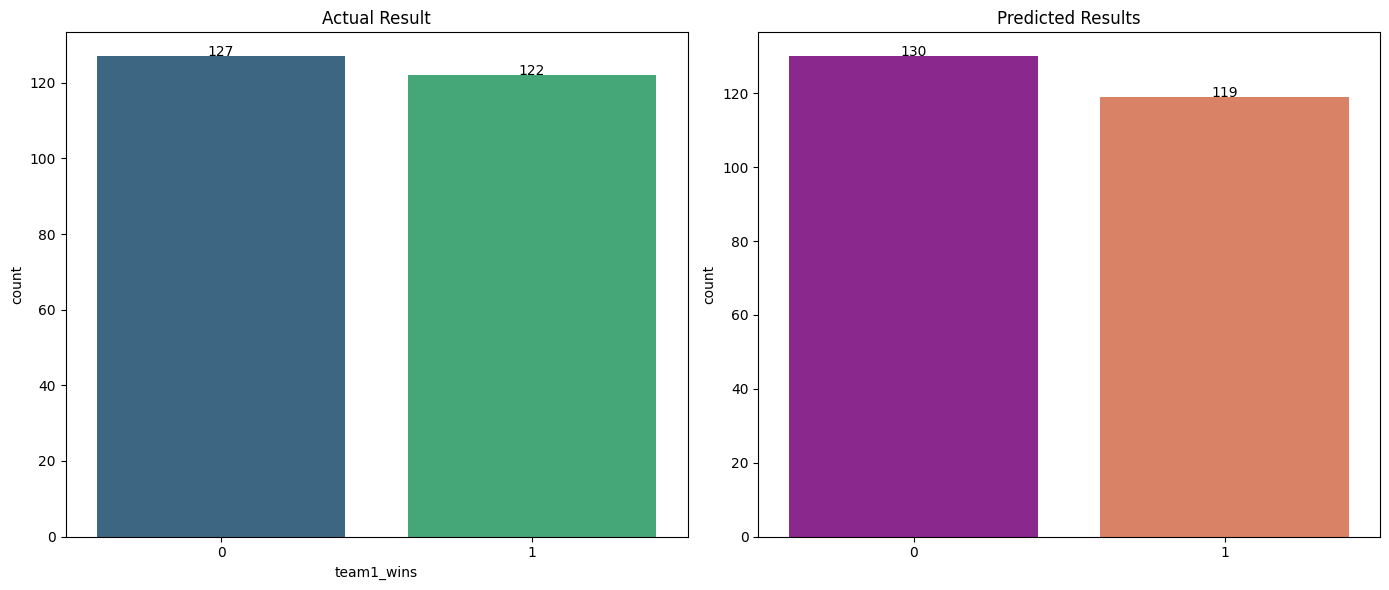

In [16]:
fig , axes =plt.subplots(1,2,figsize=(14,6))

sns.countplot(x=y_test,ax=axes[0],palette='viridis')
axes[0].set_title('Actual Result')

#print count on each bar
for  bar in axes[0].patches:
  axes[0].text(
      bar.get_x()+bar.get_width()/2,
      bar.get_height(),
      int(bar.get_height()),
      ha='center'
  )

sns.countplot(x=y_test_pred,ax=axes[1],palette='plasma')
axes[1].set_title("Predicted Results")

for  bar in axes[1].patches:
  axes[1].text(
      bar.get_x()+bar.get_width()/2,
      bar.get_height(),
      int(bar.get_height()),
      ha='center'
  )

plt.tight_layout()
plt.show()

# Model Evalution




Training Accuracy

In [18]:
y_train_pred_optimized = log_reg.predict(X_train)
print("Accuracy:")
print(accuracy_score(y_train,y_train_pred_optimized))

Accuracy:
0.7344064386317908


Testing Accuracy

In [19]:
y_test_pred_optimized = log_reg.predict(X_test)
print("Accuracy:")
print(accuracy_score(y_test,y_test_pred_optimized))

Accuracy:
0.714859437751004


Calulate Accuracy , Precision ,Recall,F1-Score

In [27]:

y_pred = log_reg.predict(X_test)
cm = confusion_matrix(y_test,y_pred)

tn,fp,fn,tp = cm.ravel()

print('\nConfusion Matrix\n')
print("Actual")
print('                    Positive Negative')
print(f'Predicted Positive:  TP={tp:3d}  FP={fp:3d}')
print(f"Predicted Negative : FN={fn:3d}  TN={tn:3d}")


Confusion Matrix

Actual
                    Positive Negative
Predicted Positive:  TP= 85  FP= 34
Predicted Negative : FN= 37  TN= 93


In [30]:
print("\nModel Evaluation")
print(f"Accuracy : {accuracy_score(y_test,y_pred):.4f}")
print(f"Precision : {precision_score(y_test,y_pred):.4f}")
print(f"recall : {recall_score(y_test,y_pred):.4f}")
print(f"F1 Score : {f1_score(y_test,y_pred):.4f}")

print("Classification Report:")
print(classification_report(y_test,y_pred))



Model Evaluation
Accuracy : 0.7149
Precision : 0.7143
recall : 0.6967
F1 Score : 0.7054
Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.73      0.72       127
           1       0.71      0.70      0.71       122

    accuracy                           0.71       249
   macro avg       0.71      0.71      0.71       249
weighted avg       0.71      0.71      0.71       249

